# Training Rectified Flow for Data-to-Data Interpolation

This notebook implements a **training pipeline** for Rectified Flow on FashionMNIST data-to-data tasks

## Core Concept

A Rectified Flow learns a neural ODE velocity field that transports a source distribution to a target distribution. We optimize:

$$\mathcal{L} = \mathbb{E}_{t \sim U[0,1], x_a, x_b} \left[ \left\| v_\theta(z_t, t) - (x_b - x_a) \right\|^2 \right]$$

where:
- $z_t = (1-t) x_a + t x_b$ (straight-line path from source to target)
- $v_\theta$ is the learned velocity field (neural network)
- Target velocity is $(x_b - x_a)$

## Key Properties

1. **Straight-line interpolation**: Data points move linearly from source to target
2. **Velocity matching**: Network learns to predict exact endpoint transformation
3. **ODE sampling**: At test time, integrate velocity forward to generate trajectories


## Prerequisite: Colab Setup

Run all cells in [`00_colab_setup.ipynb`]first! Notebook 00 owns repository cloning, working-directory setup, and the Python import path. This notebook assumes that setup is complete!

In [1]:
# check environment
import os
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'CUDA: {torch.version.cuda}')

Device: cuda
GPU: NVIDIA A100-SXM4-80GB
CUDA: 13.0


In [2]:
# core imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np
from pathlib import Path
from tqdm import tqdm
import json
from dataclasses import dataclass, field
from typing import Dict, Optional, List

import sys
from pathlib import Path

repo_path = "/content/minRF_interpolation"
assert Path(repo_path, "api", "flow_model_api.py").is_file()

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

# use project APIs
from api.flow_model_api import (
    DatasetSpec,
    ModelSpec,
    DataToDataRF,
    build_dataset_loaders,
    build_flow_model,
)
from api.checkpoint_management import CheckpointManager
from api.training_api import TrainingSpec, train_data_to_data_flow

print('Imports successful')

Imports successful


In [3]:
# disable Weights & Biases (for clean training without external logging)
os.environ['WANDB_DISABLED'] = 'true'
print('W&B disabled')

W&B disabled


## Training Configuration


### FashionMNIST Dataset Overview

FashionMNIST contains 10 classes of clothing items. Default configuration trains on:

| Class ID | Name | Role in Training |
|----------|------|------------------|
| 0 | T-shirt/top | - |
| 1 | Trouser | - |
| 2 | Pullover | - |
| 3 | Dress | - |
| 4 | Coat | - |
| 5 | Sandal | - |
| 6 | Shirt | - |
| **7** | **Sneaker** | **Source (x_a)** |
| 8 | Bag | - |
| **9** | **Ankle Boot** | **Target (x_b)** |

**Interpolation Task**: Model learns to transport images from Sneaker class to Ankle Boot class.

This pairing was chosen because both are footwear with distinct visual features, making it a meaningful semantic transformation task


In [4]:
config = TrainingSpec(
    model_profile='medium',
    source_class=7,
    target_class=9,
    train_epochs=100,
    model_name='fmnist_d2d_training',
    load_best_if_available=False,
    checkpoint_every=20,  # set to 25 for checkpoints at epochs 25, 50, ...
    validation_fraction=0.1,  # held out from the training split, not the official test set
    mixed_precision=True,  # CUDA FP16 + gradient scaling, suitable for a T4
    resume_from=None,  # set to the latest or a numbered checkpoint to continue
)
output_dir = Path('contents')
print('Configuration created')
print(f'  Source class: {config.source_class} (Sneaker)')
print(f'  Target class: {config.target_class} (Ankle Boot)')
print(f'  Model: {config.model_profile}')
print(f'  Epochs (total target, including resumed epochs): {config.train_epochs}')

Configuration created
  Source class: 7 (Sneaker)
  Target class: 9 (Ankle Boot)
  Model: medium
  Epochs (total target, including resumed epochs): 100


## Data Loading

The API uses the official FashionMNIST training split for gradient updates and reserves a stratified 10% subset of it for validation and checkpoint selection. The official test split is not used during training.

In [5]:
print('The training API splits the official training data into train and validation subsets.')
print(f'Class pair: {config.source_class} -> {config.target_class}')
print(f'Batch size: {config.batch_size} train / {config.test_batch_size} validation')

The training API builds FashionMNIST loaders once when training starts.
Class pair: 7 -> 9
Batch size: 128 train / 128 validation


## Model Initialization

In [6]:
print(f'Model profile: {config.model_profile}')
print('The training API constructs the model and optimizer via flow_model_api.')
print(f'CUDA mixed precision requested: {config.mixed_precision}')

Model profile: medium
The training API constructs the model and optimizer via flow_model_api.
CUDA mixed precision requested: True


## Training Loop

For each epoch:
1. **Forward pass**: $z_t = (1-t) x_a + t x_b$, predict $v_\theta(z_t, t)$
2. **Loss**: MSE between predicted and target velocity
3. **Backward pass**: Update model parameters
4. **Validation**: Evaluate on a held-out subset of the training split; track the best model
5. **Early stopping**: Stop if validation loss plateaus


In [7]:
print('Training entry point:', train_data_to_data_flow.__module__)
print(f'Numbered checkpoint interval: {config.checkpoint_every} epochs')

Training entry point: api.training_api
Numbered checkpoint interval: 20 epochs


In [8]:
# prepare checkpoint directory
checkpoint_dir = Path(config.checkpoint_dir)
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_manager = CheckpointManager(config.checkpoint_dir)
checkpoint_latest = checkpoint_manager.get_checkpoint_path(config.model_name, 'latest')
checkpoint_best = checkpoint_manager.get_checkpoint_path(config.model_name, 'best')

print(f'Checkpoints will be saved to: {checkpoint_dir}')

Checkpoints will be saved to: assets/fmnist_d2d_runs


In [9]:
result = train_data_to_data_flow(spec=config, device=device)
model = result['model']
flow_model = result['rf']
optimizer = result['optimizer']
train_loader = result['train_loader']
validation_loader = result['validation_loader']
test_loader = result['test_loader']
model_spec = result['setup']['model_spec']
history = {'train_loss': result['train_history'], 'val_loss': result['val_history']}
best_val_loss = result['best_val_loss']
epoch_with_best = result['best_epoch'] - 1
checkpoint_latest = result['latest_path']
checkpoint_best = result['best_path']
print(f'Model parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'Best validation loss: {best_val_loss:.6f} at epoch {epoch_with_best + 1}')

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.08MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 56.7MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.8MB/s]
/content/minRF_interpolation/api/training_api.py:153: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)


Training on cuda (NVIDIA A100-SXM4-80GB) | AMP: True | batches: 46 train, 8 val
Epoch 1/100 | train=0.309537 | val=0.196283 | best=0.196283 @ 1 | train 7.5s, val 0.6s, save 0.2s
Epoch 2/100 | train=0.168843 | val=0.134413 | best=0.134413 @ 2 | train 4.7s, val 0.6s, save 0.2s
Epoch 3/100 | train=0.134430 | val=0.114885 | best=0.114885 @ 3 | train 4.7s, val 0.6s, save 0.2s
Epoch 4/100 | train=0.106271 | val=0.095132 | best=0.095132 @ 4 | train 4.7s, val 0.6s, save 0.2s
Epoch 5/100 | train=0.094986 | val=0.085019 | best=0.085019 @ 5 | train 4.7s, val 0.6s, save 0.2s
Epoch 6/100 | train=0.085721 | val=0.080669 | best=0.080669 @ 6 | train 4.7s, val 0.6s, save 0.2s
Epoch 7/100 | train=0.079745 | val=0.073939 | best=0.073939 @ 7 | train 4.7s, val 0.6s, save 0.2s
Epoch 8/100 | train=0.071059 | val=0.070790 | best=0.070790 @ 8 | train 4.7s, val 0.6s, save 0.2s
Epoch 9/100 | train=0.071787 | val=0.074625 | best=0.070790 @ 8 | train 4.7s, val 0.6s, save 0.1s
Epoch 10/100 | train=0.068956 | val=0.

## Training Summary

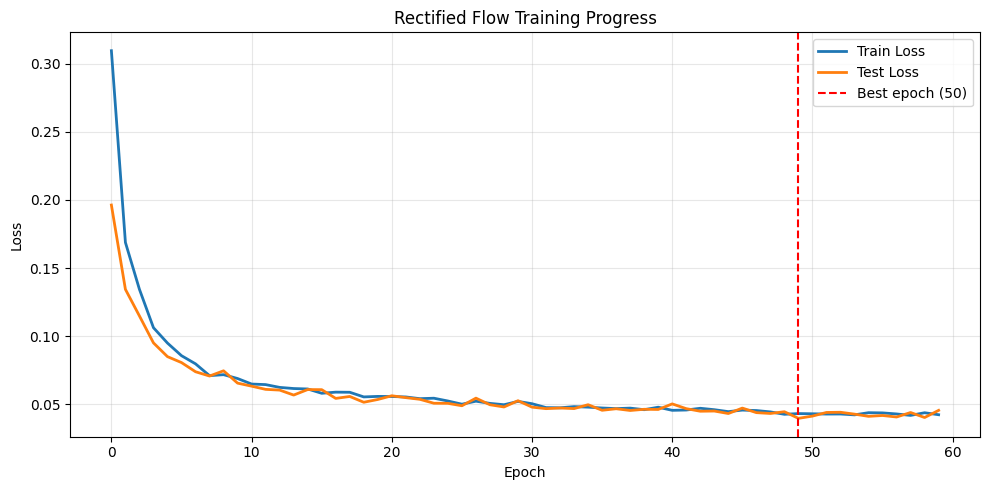

Training curve saved


In [14]:
import matplotlib.pyplot as plt

# plot training curves
plt.figure(figsize=(10, 5))
plt.plot(history['train_loss'], label='Train Loss', linewidth=2)
plt.plot(history['val_loss'], label='Validation Loss', linewidth=2)
plt.axvline(x=epoch_with_best, color='red', linestyle='--', label=f'Best epoch ({epoch_with_best+1})')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Rectified Flow Training Progress')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / 'training_curves.png', dpi=150)
plt.show()

print(f'Training curve saved')

In [15]:
# save training history
history_file = output_dir / 'training_history.json'
with open(history_file, 'w') as f:
    json.dump(history, f, indent=2)

print(f'History saved to {history_file}')

History saved to contents/training_history.json


In [16]:
# print final statistics
print('\n' + '='*60)
print('TRAINING COMPLETED')
print('='*60)
print(f'Total epochs trained: {len(history["train_loss"])}')
print(f'Best epoch: {epoch_with_best + 1}')
print(f'Best validation loss: {best_val_loss:.6f}')
print(f'Final train loss: {history["train_loss"][-1]:.6f}')
print(f'Final validation loss: {history["val_loss"][-1]:.6f}')
print(f'\nCheckpoint saved: {checkpoint_best}')
print('='*60)


TRAINING COMPLETED
Total epochs trained: 60
Best epoch: 50
Best test loss: 0.039741
Final train loss: 0.042391
Final test loss: 0.045592

Checkpoint saved: assets/fmnist_d2d_runs/fmnist_d2d_training_checkpoint_best.pt


## Load Best Model for Evaluation


In [17]:
# load best checkpoint for subsequent evaluation
# recreate model and optimizer
best_model, _, best_optimizer = build_flow_model(model_spec)
best_model = best_model.to(device)

# load checkpoint state
checkpoint = checkpoint_manager.load_checkpoint(
    best_model, config.model_name, checkpoint_type='best', device=device,
    load_optimizer=True, optimizer=best_optimizer
)

best_flow_model = DataToDataRF(best_model)

print(f'Best model loaded from epoch {epoch_with_best + 1}')
print(f'Validation loss at that epoch: {best_val_loss:.6f}')

Best model loaded from epoch 50
Test loss at that epoch: 0.039741
